# Stroke Prediction Using Machine Learning
**DATA 4380 — Final Tabular-Data Project**

**Research Question:** Can machine-learning models predict stroke occurrence from demographic, clinical, and lifestyle characteristics while properly handling missing data and class imbalance?

## 1. Import Libraries

This step loads the tools used for data analysis, preprocessing, visualization, model training, and evaluation.  
The code also installs `imbalanced-learn` automatically only if it is missing.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import imblearn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

## 2. Load the Dataset

The dataset is loaded from the notebook folder first, with `/mnt/data` used as a backup location.  
The first five rows are displayed to confirm that the file loaded correctly.

In [2]:
possible_paths = [
    Path("healthcare-dataset-stroke-data.csv"),
    Path("/mnt/data/healthcare-dataset-stroke-data.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Place healthcare-dataset-stroke-data.csv in the same folder as this notebook."
    )

df = pd.read_csv(data_path)

print(f"Loaded: {data_path}")
print(f"Shape: {df.shape}")
display(df.head())

Loaded: healthcare-dataset-stroke-data.csv
Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Initial Data Audit

Before modeling, the dataset is checked for data types, missing values, duplicate rows, and unique values.  
This identifies the main preprocessing problems before any information is used by a model.

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})

display(audit)
print("Duplicate rows:", df.duplicated().sum())

,dtype,missing,missing_pct,unique_values
id,int64,0,0.00,5110
gender,object,0,0.00,3
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,object,0,0.00,2
work_type,object,0,0.00,5
Residence_type,object,0,0.00,2
avg_glucose_level,float64,0,0.00,3979
bmi,float64,201,3.93,418


Duplicate rows: 0


## 4. Descriptive Statistics

Numerical and categorical summaries provide an overview of the patient population and variable ranges.  
These summaries also help identify unusual values and confirm which variables are numeric or categorical.

In [4]:
print("Numerical Summary")
display(df.describe(include=[np.number]).T)

print("Categorical Summary")
display(df.describe(include=["object"]).T)

Numerical Summary


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


Categorical Summary


,count,unique,top,freq
gender,5110,3,Female,2994
ever_married,5110,2,Yes,3353
work_type,5110,5,Private,2925
Residence_type,5110,2,Urban,2596
smoking_status,5110,4,never smoked,1892


## 5. Examine the Target Variable

The target variable is `stroke`, where 1 means a stroke event and 0 means no stroke event.  
Because stroke cases are rare, a high accuracy score can be misleading if the model predicts mostly non-stroke cases.

,Count,Percent
stroke,,
0,4861,95.13
1,249,4.87


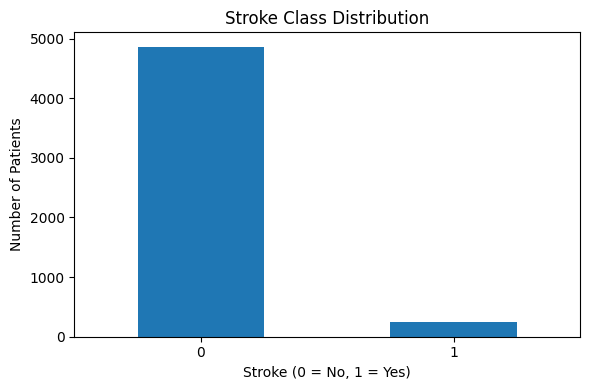

Majority-class accuracy: 0.9513


In [5]:
target_counts = df["stroke"].value_counts().sort_index()
target_percent = (df["stroke"].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percent": target_percent
})

display(target_summary)

plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Stroke Class Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

majority_accuracy = target_counts.max() / target_counts.sum()
print(f"Majority-class accuracy: {majority_accuracy:.4f}")

## 6. Missing and Unavailable Values

BMI contains actual missing values, while smoking status uses `"Unknown"` as an explicit category for unavailable information.  
The project keeps the `"Unknown"` category and imputes BMI later inside the preprocessing pipeline.

In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
display(missing_summary[missing_summary["Missing_Count"] > 0])

smoking_summary = df["smoking_status"].value_counts(dropna=False)
display(smoking_summary.to_frame("Count"))

unknown_smoking = (df["smoking_status"] == "Unknown").sum()
print(f"Unknown smoking status: {unknown_smoking} ({unknown_smoking/len(df)*100:.2f}%)")

,Missing_Count,Missing_Percent
bmi,201,3.93


,Count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


Unknown smoking status: 1544 (30.22%)


## 7. Exploratory Data Analysis — Numerical Variables

Age, average glucose level, and BMI are examined using histograms and boxplots by stroke status.  
These plots help visualize distribution differences, but they are descriptive and do not prove causation.

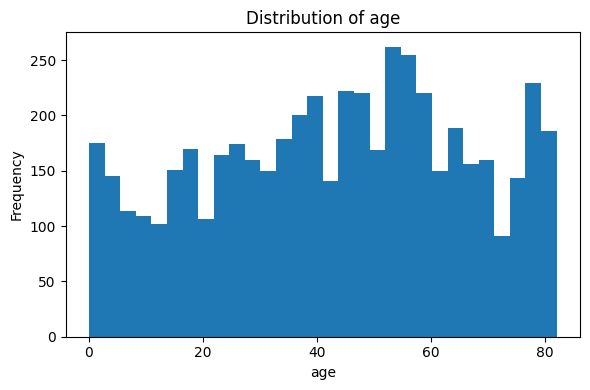

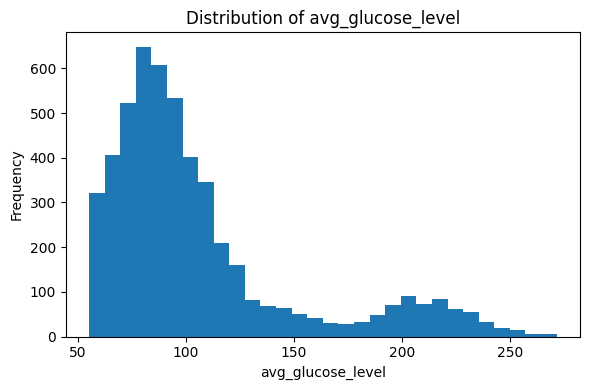

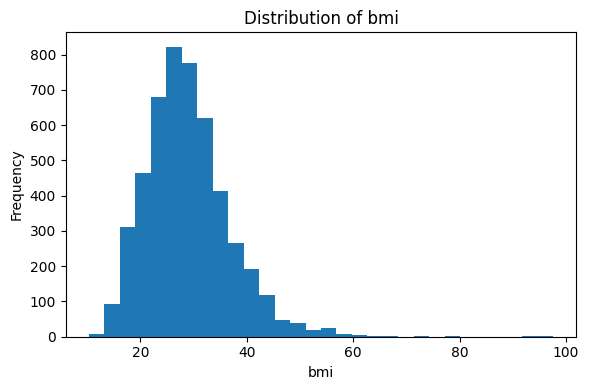

<Figure size 600x400 with 0 Axes>

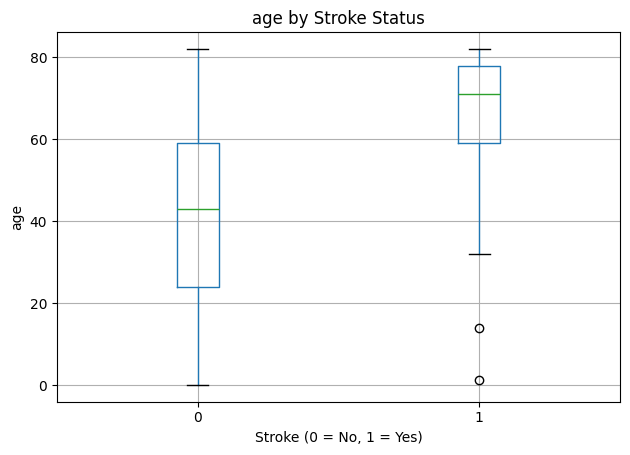

<Figure size 600x400 with 0 Axes>

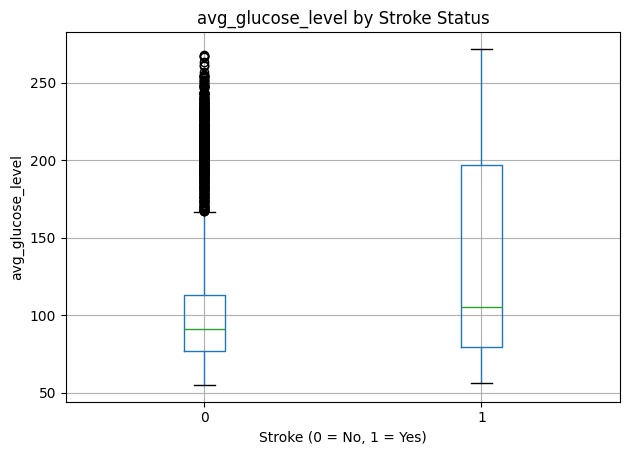

<Figure size 600x400 with 0 Axes>

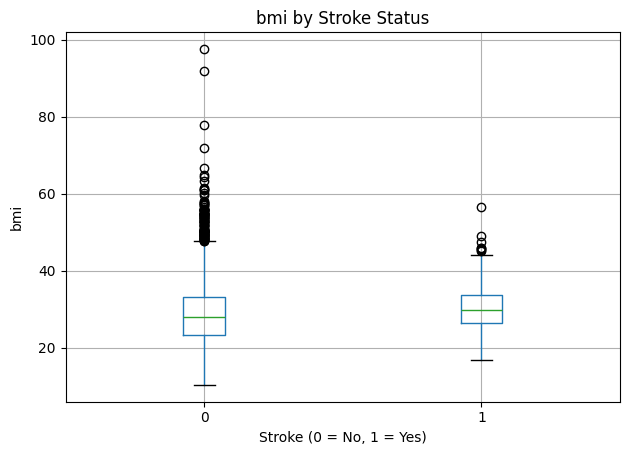

In [7]:
numeric_plot_cols = ["age", "avg_glucose_level", "bmi"]

for col in numeric_plot_cols:
    plt.figure(figsize=(6, 4))
    df[col].dropna().plot(kind="hist", bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

for col in numeric_plot_cols:
    plt.figure(figsize=(6, 4))
    df.boxplot(column=col, by="stroke")
    plt.title(f"{col} by Stroke Status")
    plt.suptitle("")
    plt.xlabel("Stroke (0 = No, 1 = Yes)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 8. Exploratory Data Analysis — Stroke Rates by Category

Stroke rates are calculated for important demographic and clinical categories.  
Using percentages instead of only raw counts makes categories of different sizes easier to compare.

Stroke rate by gender


,count,stroke_rate_percent
gender,,
Female,2994,4.71
Male,2115,5.11
Other,1,0.00


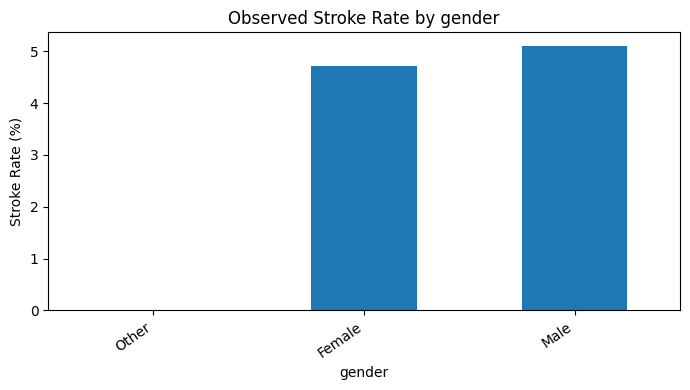

Stroke rate by hypertension


,count,stroke_rate_percent
hypertension,,
0,4612,3.97
1,498,13.25


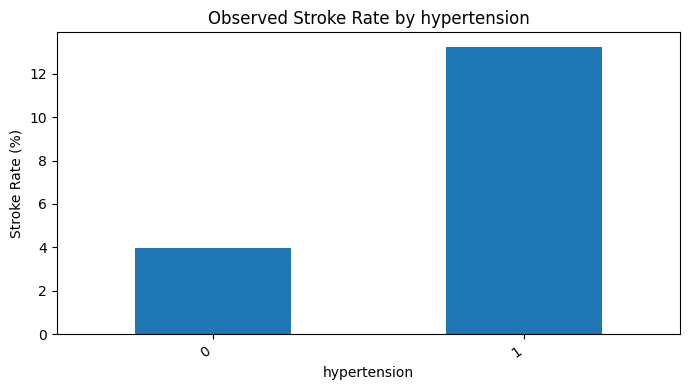

Stroke rate by heart_disease


,count,stroke_rate_percent
heart_disease,,
0,4834,4.18
1,276,17.03


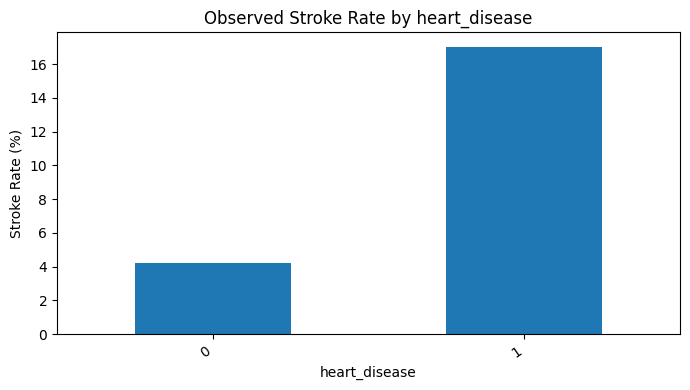

Stroke rate by ever_married


,count,stroke_rate_percent
ever_married,,
No,1757,1.65
Yes,3353,6.56


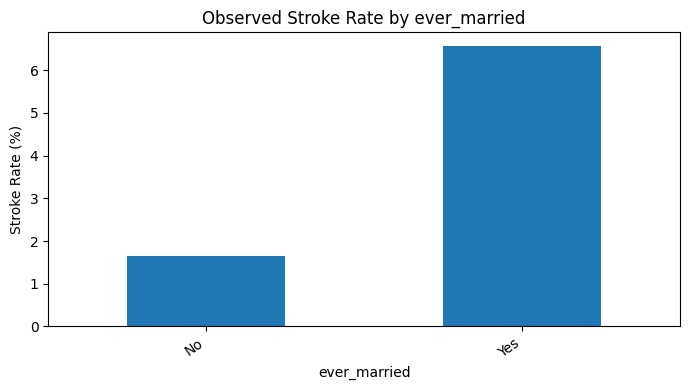

Stroke rate by work_type


,count,stroke_rate_percent
work_type,,
Govt_job,657,5.02
Never_worked,22,0.00
Private,2925,5.09
Self-employed,819,7.94
children,687,0.29


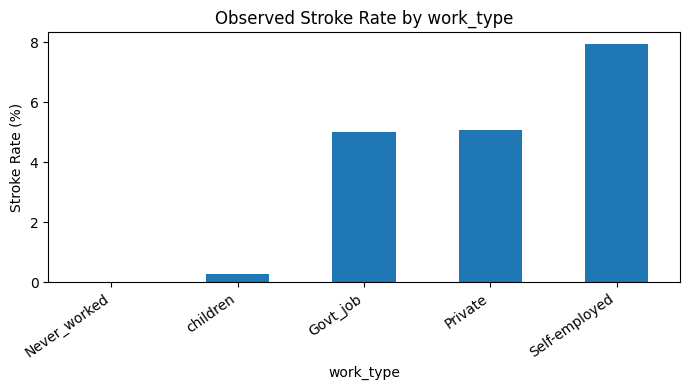

Stroke rate by Residence_type


,count,stroke_rate_percent
Residence_type,,
Rural,2514,4.53
Urban,2596,5.20


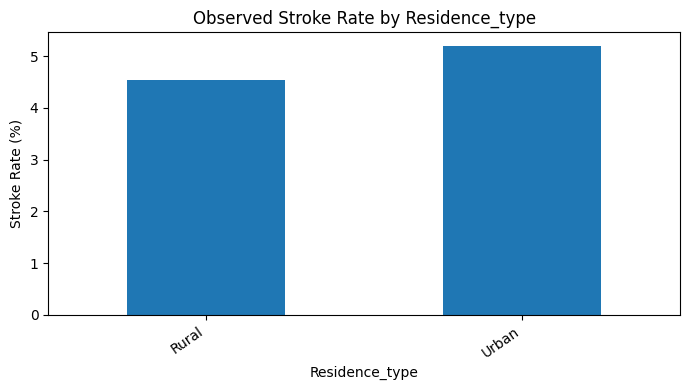

Stroke rate by smoking_status


,count,stroke_rate_percent
smoking_status,,
Unknown,1544,3.04
formerly smoked,885,7.91
never smoked,1892,4.76
smokes,789,5.32


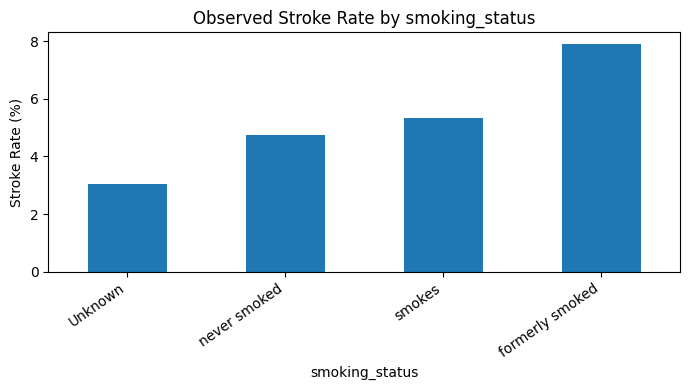

In [8]:
categorical_rate_cols = [
    "gender", "hypertension", "heart_disease", "ever_married",
    "work_type", "Residence_type", "smoking_status"
]

for col in categorical_rate_cols:
    summary = (
        df.groupby(col, dropna=False)["stroke"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "stroke_rate"})
    )
    summary["stroke_rate_percent"] = (summary["stroke_rate"] * 100).round(2)

    print(f"Stroke rate by {col}")
    display(summary[["count", "stroke_rate_percent"]])

    plt.figure(figsize=(7, 4))
    summary["stroke_rate_percent"].sort_values().plot(kind="bar")
    plt.title(f"Observed Stroke Rate by {col}")
    plt.ylabel("Stroke Rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## 9. Prepare the Modeling Dataset

The `id` column is removed because it is only a record identifier and does not describe patient health.  
BMI is converted to numeric so missing values can be handled correctly by the preprocessing pipeline.

In [9]:
model_df = df.copy()

model_df = model_df.drop(columns=["id"])
model_df["bmi"] = pd.to_numeric(model_df["bmi"], errors="coerce")

X = model_df.drop(columns=["stroke"])
y = model_df["stroke"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (5110, 10)
Target shape: (5110,)


## 10. Stratified Train/Test Split

The data are split 80/20 using stratification so the stroke proportion remains similar in both sets.  
The test set is kept untouched during preprocessing, model selection, cross-validation, and tuning.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print(f"Training stroke rate: {y_train.mean():.4f}")
print(f"Test stroke rate: {y_test.mean():.4f}")

Training shape: (4088, 10)
Test shape: (1022, 10)
Training stroke rate: 0.0487
Test stroke rate: 0.0489


## 11. Build the Leakage-Safe Preprocessing Pipeline

Numerical features use median imputation and standardization, while categorical features use imputation and one-hot encoding.  
Placing these steps inside a pipeline ensures preprocessing is learned from training data only, reducing data leakage.

In [11]:
numeric_features = ["age", "avg_glucose_level", "bmi"]

categorical_features = [
    "gender", "hypertension", "heart_disease", "ever_married",
    "work_type", "Residence_type", "smoking_status"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


## 12. Create a Dummy Baseline

A majority-class Dummy Classifier establishes the minimum benchmark that real models should beat.  
This also demonstrates why accuracy alone is not enough for a dataset with only a small percentage of stroke cases.

In [12]:
dummy_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

dummy_pipeline.fit(X_train, y_train)

dummy_pred = dummy_pipeline.predict(X_test)
dummy_prob = dummy_pipeline.predict_proba(X_test)[:, 1]

dummy_result = {
    "Model": "Dummy Majority",
    "Accuracy": accuracy_score(y_test, dummy_pred),
    "Precision": precision_score(y_test, dummy_pred, zero_division=0),
    "Recall": recall_score(y_test, dummy_pred, zero_division=0),
    "F1": f1_score(y_test, dummy_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, dummy_prob),
    "PR_AUC": average_precision_score(y_test, dummy_prob)
}

display(pd.DataFrame([dummy_result]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Dummy Majority,0.9511,0.0,0.0,0.0,0.5,0.0489


## 13. Train Multiple Models

Several models are compared because they make different assumptions about the relationship between predictors and stroke status.  
Class weighting is used for models that support it so the rare stroke class receives more attention during training.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
test_results = [dummy_result]

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "PR_AUC": average_precision_score(y_test, prob)
    })

results_df = pd.DataFrame(test_results).sort_values("PR_AUC", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Logistic Regression,0.7466,0.1384,0.80,0.2360,0.8437,0.2683
5,Gradient Boosting,0.9511,0.5000,0.04,0.0741,0.8343,0.2110
4,SVM,0.7622,0.1274,0.66,0.2136,0.8016,0.1736
2,Decision Tree,0.8278,0.1786,0.70,0.2846,0.8192,0.1625
3,Random Forest,0.9501,0.0000,0.00,0.0000,0.7786,0.1360
0,Dummy Majority,0.9511,0.0000,0.00,0.0000,0.5000,0.0489


## 14. Five-Fold Stratified Cross-Validation

Five-fold stratified cross-validation checks whether model performance is consistent across multiple subsets of the training data.  
The test set remains untouched, while each fold preserves approximately the same stroke proportion.

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "ROC_AUC": "roc_auc",
    "PR_AUC": "average_precision",
    "Recall": "recall",
    "F1": "f1"
}

cv_rows = []

for name, pipeline in fitted_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        "CV_ROC_AUC": scores["test_ROC_AUC"].mean(),
        "CV_PR_AUC": scores["test_PR_AUC"].mean(),
        "CV_Recall": scores["test_Recall"].mean(),
        "CV_F1": scores["test_F1"].mean()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV_PR_AUC", ascending=False)
display(cv_results_df.round(4))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 112, in start_daemon
RuntimeError: Failed to start artifact tool daemon (exited early)


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 112, in start_daemon
RuntimeError: Failed to start artifact tool daemon (exited early)


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 112, in start_daemon
RuntimeError: Failed to start artifact tool daemon (exited early)


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 776, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 62, in _populate_warmup_workbook
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/generated/interface/models.py", line 31668, in get_range
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/remote.py", line 749, in __call__
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/client.py", line 135, in call
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/client.py", line 115, in _recv_one_line
artifact_tool.rpc.client.TransportError: RPC connecti

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 720, in _warm_feature_flows
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 704, in _warm_collaboration_flows
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/generated/interface/models.py", line 32317, in hydrate_crdt_from_proto
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/remote.py", line 749, in __call__
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/client.py", line 150, in call
artifact_tool.rpc.client.

,Model,CV_ROC_AUC,CV_PR_AUC,CV_Recall,CV_F1
4,Gradient Boosting,0.8428,0.1951,0.0201,0.0372
0,Logistic Regression,0.8387,0.1930,0.7890,0.2277
2,Random Forest,0.8026,0.1573,0.0050,0.0091
3,SVM,0.7951,0.1546,0.6683,0.2053
1,Decision Tree,0.7779,0.1373,0.7628,0.2041


## 15. Compare Class Weighting with SMOTE

SMOTE creates synthetic minority-class examples to reduce class imbalance during training.  
It is placed inside the training pipeline after preprocessing so synthetic examples never contaminate the test set.

In [15]:
smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

smote_pipeline.fit(X_train, y_train)

smote_pred = smote_pipeline.predict(X_test)
smote_prob = smote_pipeline.predict_proba(X_test)[:, 1]

smote_result = {
    "Model": "Logistic Regression + SMOTE",
    "Accuracy": accuracy_score(y_test, smote_pred),
    "Precision": precision_score(y_test, smote_pred, zero_division=0),
    "Recall": recall_score(y_test, smote_pred, zero_division=0),
    "F1": f1_score(y_test, smote_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, smote_prob),
    "PR_AUC": average_precision_score(y_test, smote_prob)
}

display(pd.DataFrame([smote_result]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression + SMOTE,0.7476,0.1389,0.8,0.2367,0.8441,0.2835


## 16. Hyperparameter Tuning

Logistic Regression is tuned using GridSearchCV and average precision as the optimization metric.  
Only the training data are used for tuning so the final test evaluation remains independent.

In [16]:
tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"]
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(f"Best CV PR-AUC: {grid_search.best_score_:.4f}")

Best parameters: {'model__C': 100, 'model__penalty': 'l2'}
Best CV PR-AUC: 0.1933


## 17. Final Test-Set Evaluation

The tuned model is evaluated once on the untouched test set using several metrics and a confusion matrix.  
Recall and PR-AUC are emphasized because the positive stroke class is rare and clinically important to detect.

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,0.7466,0.1384,0.8,0.236,0.8439,0.2683


              precision    recall  f1-score   support

           0     0.9864    0.7438    0.8481       972
           1     0.1384    0.8000    0.2360        50

    accuracy                         0.7466      1022
   macro avg     0.5624    0.7719    0.5420      1022
weighted avg     0.9449    0.7466    0.8181      1022



,Predicted No Stroke,Predicted Stroke
Actual No Stroke,723,249
Actual Stroke,10,40


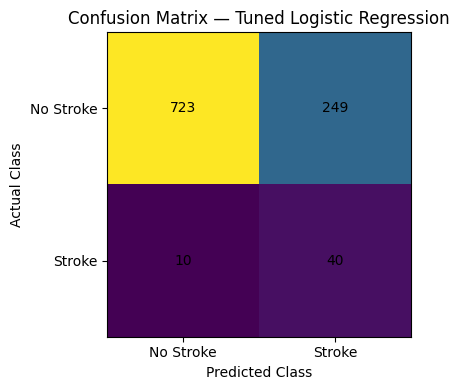

In [17]:
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

final_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, best_pred),
    "Precision": precision_score(y_test, best_pred, zero_division=0),
    "Recall": recall_score(y_test, best_pred, zero_division=0),
    "F1": f1_score(y_test, best_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, best_prob),
    "PR_AUC": average_precision_score(y_test, best_prob)
}])

display(final_metrics.round(4))

print(classification_report(y_test, best_pred, digits=4))

cm = confusion_matrix(y_test, best_pred)
cm_df = pd.DataFrame(
    cm,
    index=["Actual No Stroke", "Actual Stroke"],
    columns=["Predicted No Stroke", "Predicted Stroke"]
)
display(cm_df)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix — Tuned Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1], ["No Stroke", "Stroke"])
plt.yticks([0, 1], ["No Stroke", "Stroke"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## 18. ROC and Precision–Recall Curves

The ROC curve summarizes sensitivity versus false-positive rate across thresholds, while the Precision–Recall curve focuses more directly on the positive class.  
For this imbalanced dataset, the Precision–Recall curve is especially useful for understanding minority-class performance.

<Figure size 600x500 with 0 Axes>

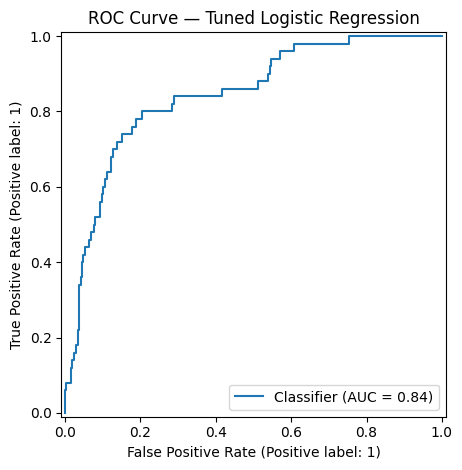

<Figure size 600x500 with 0 Axes>

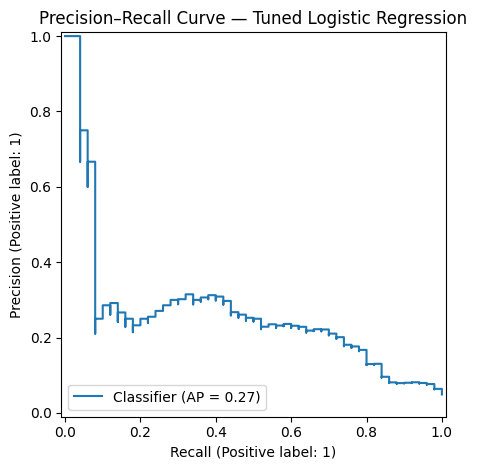

In [18]:
plt.figure(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title("ROC Curve — Tuned Logistic Regression")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, best_prob)
plt.title("Precision–Recall Curve — Tuned Logistic Regression")
plt.tight_layout()
plt.show()

## 19. Threshold Analysis

The default classification threshold of 0.50 is not the only possible decision point.  
This step shows how precision and recall change when the probability threshold becomes more or less strict.

In [19]:
threshold_rows = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_pred = (best_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1": f1_score(y_test, threshold_pred, zero_division=0),
        "Predicted_Positive": int(threshold_pred.sum())
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,Predicted_Positive
0,0.2,0.0833,0.86,0.1519,516
1,0.3,0.0974,0.84,0.1746,431
2,0.4,0.1190,0.84,0.2084,353
3,0.5,0.1384,0.80,0.2360,289
4,0.6,0.1711,0.78,0.2806,228
5,0.7,0.2034,0.72,0.3172,177


## 20. Feature Interpretation

Logistic Regression coefficients are matched to the transformed feature names so the final model can be interpreted.  
Positive coefficients push predictions toward stroke, while negative coefficients push predictions away from stroke within this model.

,Feature,Coefficient,Absolute_Coefficient
13,cat__work_type_Never_worked,-2.036410,2.036410
0,num__age,1.898062,1.898062
16,cat__work_type_children,1.249802,1.249802
5,cat__gender_Other,-1.042116,1.042116
6,cat__hypertension_0,-0.507813,0.507813
3,cat__gender_Female,0.378050,0.378050
21,cat__smoking_status_never smoked,-0.352713,0.352713
8,cat__heart_disease_0,-0.323218,0.323218
11,cat__ever_married_Yes,-0.289317,0.289317
17,cat__Residence_type_Rural,-0.285277,0.285277


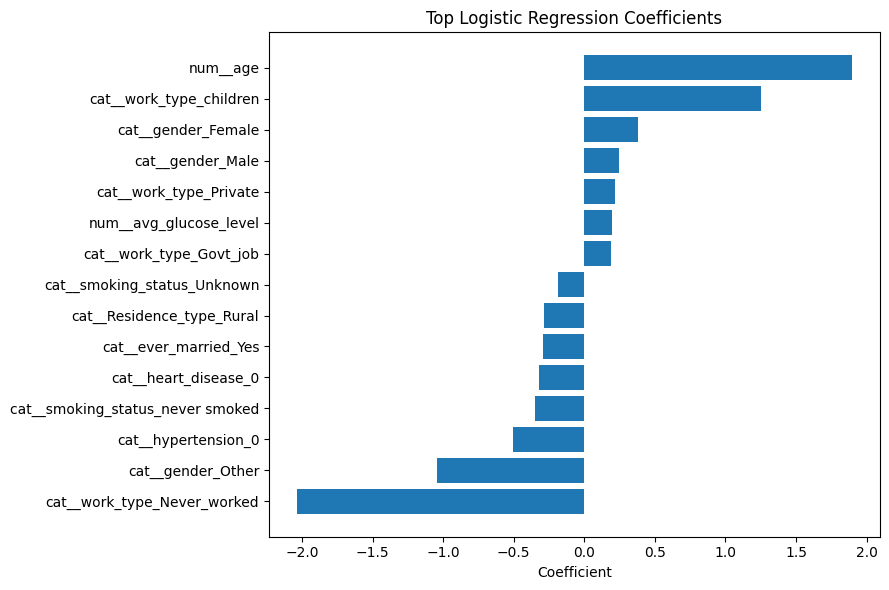

In [20]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": np.abs(coefficients)
}).sort_values("Absolute_Coefficient", ascending=False)

display(coef_df.head(20))

top_coef = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(9, 6))
plt.barh(top_coef["Feature"], top_coef["Coefficient"])
plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

## 21. Error Analysis

False negatives and false positives are extracted from the held-out test set for direct inspection.  
This helps explain where the model struggles instead of relying only on one summary score.

In [21]:
error_df = X_test.copy()
error_df["actual_stroke"] = y_test.values
error_df["predicted_stroke"] = best_pred
error_df["predicted_probability"] = best_prob

false_negatives = error_df[
    (error_df["actual_stroke"] == 1) &
    (error_df["predicted_stroke"] == 0)
].sort_values("predicted_probability")

false_positives = error_df[
    (error_df["actual_stroke"] == 0) &
    (error_df["predicted_stroke"] == 1)
].sort_values("predicted_probability", ascending=False)

print("False negatives:", len(false_negatives))
display(false_negatives.head(10))

print("False positives:", len(false_positives))
display(false_positives.head(10))

False negatives: 10


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,actual_stroke,predicted_stroke,predicted_probability
245,Female,14.0,0,0,No,children,Rural,57.93,30.9,Unknown,1,0,0.052681
182,Female,32.0,0,0,Yes,Private,Rural,76.13,29.9,smokes,1,0,0.103340
210,Female,39.0,0,0,Yes,Private,Urban,83.24,26.3,never smoked,1,0,0.127912
31,Male,42.0,0,0,Yes,Private,Rural,83.41,25.4,Unknown,1,0,0.142924
94,Male,45.0,0,0,Yes,Private,Rural,64.14,29.4,never smoked,1,0,0.146448
133,Female,38.0,0,0,Yes,Private,Rural,101.45,NaN,formerly smoked,1,0,0.149017
228,Female,39.0,0,0,Yes,Self-employed,Urban,97.76,29.6,smokes,1,0,0.170973
88,Male,47.0,0,0,Yes,Private,Urban,86.94,41.1,formerly smoked,1,0,0.280384
38,Male,58.0,0,0,No,Private,Rural,92.62,32.0,Unknown,1,0,0.449632
80,Male,59.0,0,0,Yes,Private,Rural,96.16,44.1,Unknown,1,0,0.455462


False positives: 249


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,actual_stroke,predicted_stroke,predicted_probability
3318,Male,81.0,1,1,No,Private,Rural,220.64,30.0,never smoked,0,1,0.949594
894,Male,81.0,1,0,Yes,Self-employed,Urban,231.19,31.6,formerly smoked,0,1,0.944201
4763,Male,82.0,0,0,Yes,Private,Urban,217.57,33.5,formerly smoked,0,1,0.925523
2453,Male,82.0,0,0,Yes,Private,Urban,214.42,33.9,formerly smoked,0,1,0.924754
2102,Male,78.0,1,1,Yes,Self-employed,Rural,199.88,29.6,formerly smoked,0,1,0.924215
2979,Female,82.0,1,0,Yes,Self-employed,Urban,107.21,27.0,formerly smoked,0,1,0.921967
3317,Female,81.0,1,0,Yes,Private,Rural,164.77,34.5,never smoked,0,1,0.921911
3643,Male,81.0,0,0,Yes,Private,Urban,234.35,25.3,formerly smoked,0,1,0.920805
1776,Female,78.0,1,0,Yes,Private,Rural,91.63,33.5,smokes,0,1,0.916266
1780,Female,81.0,1,0,Yes,Self-employed,Rural,210.23,30.7,never smoked,0,1,0.916227


## 22. Final Model Comparison

The final table places all main test-set results, including the SMOTE experiment, in one location.  
Sorting by PR-AUC makes the comparison more appropriate for the rare stroke class while still showing all other metrics.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
6,Logistic Regression + SMOTE,0.7476,0.1389,0.80,0.2367,0.8441,0.2835
1,Logistic Regression,0.7466,0.1384,0.80,0.2360,0.8437,0.2683
5,Gradient Boosting,0.9511,0.5000,0.04,0.0741,0.8343,0.2110
4,SVM,0.7622,0.1274,0.66,0.2136,0.8016,0.1736
2,Decision Tree,0.8278,0.1786,0.70,0.2846,0.8192,0.1625
3,Random Forest,0.9501,0.0000,0.00,0.0000,0.7786,0.1360
0,Dummy Majority,0.9511,0.0000,0.00,0.0000,0.5000,0.0489


<Figure size 1100x600 with 0 Axes>

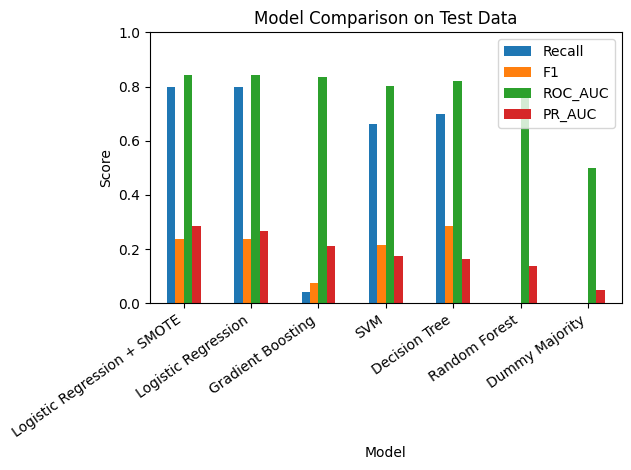

In [22]:
final_comparison = pd.concat([
    pd.DataFrame(test_results),
    pd.DataFrame([smote_result])
], ignore_index=True).sort_values("PR_AUC", ascending=False)

display(final_comparison.round(4))

plot_df = final_comparison.set_index("Model")[["Recall", "F1", "ROC_AUC", "PR_AUC"]]

plt.figure(figsize=(11, 6))
plot_df.plot(kind="bar")
plt.title("Model Comparison on Test Data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 23. Final Conclusions

- Stroke prediction is a strongly imbalanced binary-classification problem in this dataset.
- A majority-class model can achieve high accuracy while identifying no stroke cases, so accuracy alone is not sufficient.
- A leakage-safe preprocessing pipeline was used for imputation, scaling, and categorical encoding.
- Class weighting and SMOTE were compared as two different imbalance strategies.
- Stratified cross-validation and GridSearchCV were used before final test-set evaluation.
- Logistic Regression provided a strong balance of interpretability and minority-class recall.
- Results should be interpreted as predictive associations, not causal or clinical diagnostic conclusions.

### Limitations
- Only a small number of records are stroke-positive.
- BMI has missing values and smoking status contains many `"Unknown"` entries.
- The data are observational and come from a single educational dataset.
- External validation would be required before any real clinical use.